# 09 · Alveolar epithelial trajectories: AT2 → transitional → AT1 or aberrant basaloid

**Biological question.** After injury, AT2 cells act as alveolar stem cells:
they proliferate and differentiate into AT1 cells through a KRT8-high
*transitional* state (mouse: Strunz *et al.* 2020; Kobayashi *et al.* 2020;
Choi *et al.* 2020). In IPF lungs, Habermann *et al.* and Adams *et al.* (2020)
described **aberrant basaloid (KRT5⁻/KRT17⁺) cells** that line fibroblastic foci
and appear to be a *pathological end point* of failed AT2-to-AT1
differentiation. We test whether the data support this lineage structure and
which genes track the commitment towards the aberrant state.

**Methods and caveats**
* **PAGA** (Wolf *et al.* 2019): graph abstraction showing which cell types are
  connected at all in the kNN graph.
* **Diffusion pseudotime** (DPT; Haghverdi *et al.* 2016) from a mature AT2 root.
* **CellRank 2** (Weiler *et al.* 2024) with a **pseudotime kernel**: transitions
  are biased towards increasing DPT, i.e. away from AT2 cells, the established
  progenitors of the alveolar epithelium (lineage tracing in mice, Barkauskas
  *et al.* 2013; human AT2 organoids). The direction is therefore an *assumption*
  taken from that literature; the data decide where cells go. The 5′ data have no
  reliable spliced/unspliced information for RNA velocity (5′ chemistry captures
  transcript starts, not intronic reads near 3′ ends).
* **CytoTRACE** (Gulati *et al.* 2020), which orients differentiation by
  transcriptional diversity, is computed as a diagnostic but **not used for the
  direction**: it ranks aberrant basaloid cells as the most potent cells of the
  lineage (they are large, transcriptionally active cells), which contradicts
  their senescence-like phenotype, and with it every cell, AT1 included, flowed
  into the aberrant basaloid state.
* **Snapshot caveat.** scRNA-seq of human tissue is a snapshot: a trajectory is a
  *hypothesis about ordering* consistent with transcriptional similarity, not a
  demonstration of lineage (which needs lineage tracing, possible only in mice).

GPCCA (pyGPCCA) needs a Schur decomposition of the transition matrix. Without
PETSc/SLEPc (not available on Windows) the dense method is used, so cells are
subsampled to ≤1,800 per cell type, which keeps rare states fully represented.

In [1]:
import anndata as ad
import cellrank as cr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv

from ipfatlas import annotation, pseudobulk
from ipfatlas.config import rscript, setup
from ipfatlas.plotting import (
    CONDITION_COLORS,
    LINEAGE_COLORS,
    embedding_scatter,
    figsize,
    label_centroids,
    panel_label,
    save_figure,
    set_style,
)
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "09_trajectory"
TAB = P.tables / "09_trajectory"
LINEAGE = cfg["trajectory"]["lineage"]
CAP = 1800

full = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
colors = LINEAGE_COLORS
pd.crosstab(full.obs.loc[full.obs.cell_type.isin(LINEAGE), "cell_type"].astype(str),
            full.obs.loc[full.obs.cell_type.isin(LINEAGE), "diagnosis"])

diagnosis,Control,ILD,IPF,NSIP,Sarcoidosis,cHP
cell_type,,,,,,
AT1,659,18,497,204,39,72
AT2,4615,524,4372,586,688,448
Aberrant basaloid,42,26,348,5,10,51
Basal,55,25,1388,53,2,113
Transitional AT2,138,16,294,8,5,24


## 1. Lineage subset (stratified subsample)

In [2]:
rng = np.random.default_rng(0)
idx = []
for ct in LINEAGE:
    cells = np.where(full.obs["cell_type"] == ct)[0]
    idx.extend(rng.choice(cells, min(CAP, len(cells)), replace=False))
adata = full[np.sort(idx)].copy()
adata.obs["cell_type"] = adata.obs["cell_type"].cat.remove_unused_categories()
adata.uns["cell_type_colors"] = [colors[c] for c in adata.obs["cell_type"].cat.categories]
print(adata.obs["cell_type"].value_counts())

sc.pp.neighbors(adata, use_rep="X_integrated", n_neighbors=30, random_state=0)
sc.tl.paga(adata, groups="cell_type")
sc.pl.paga(adata, show=False, threshold=0.1)
plt.close()
sc.tl.umap(adata, init_pos="paga", min_dist=0.3, random_state=0)
sc.tl.diffmap(adata, n_comps=15)

cell_type
AT2                  1800
Basal                1636
AT1                  1489
Transitional AT2      485
Aberrant basaloid     482
Name: count, dtype: int64


## 2. PAGA connectivity
Edge weight = how much more connected two cell types are in the kNN graph than
expected by chance. A path AT2 → transitional AT2 → AT1 and a branch from the
transitional state to aberrant basaloid cells is the pattern predicted by the
mouse injury models.

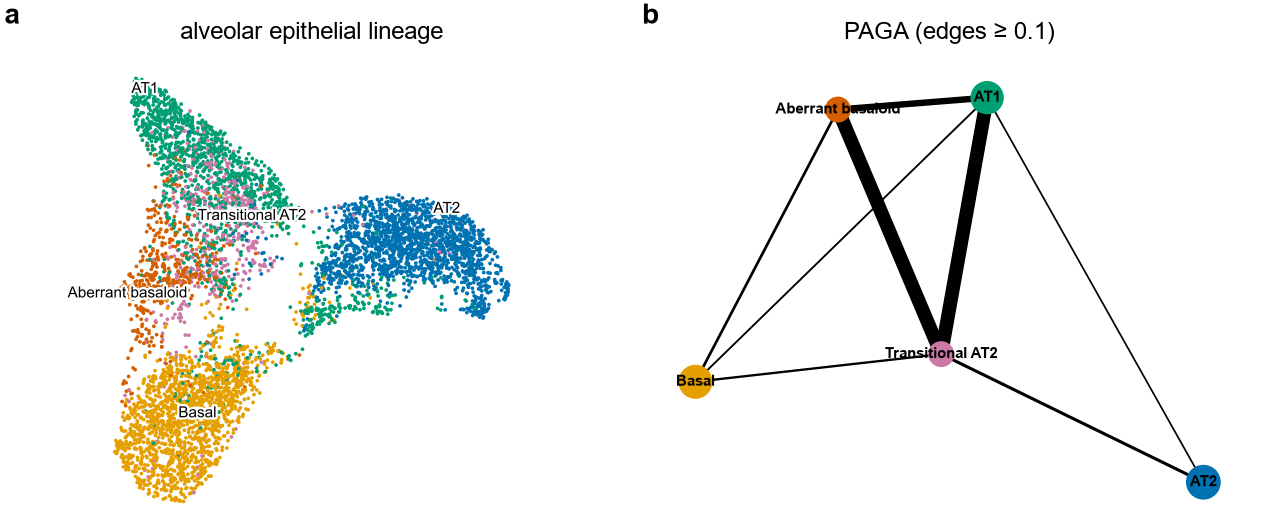

,AT1,AT2,Transitional AT2,Aberrant basaloid,Basal
AT1,0.00,0.12,1.00,0.47,0.14
AT2,0.12,0.00,0.23,0.02,0.02
Transitional AT2,1.00,0.23,0.00,1.00,0.17
Aberrant basaloid,0.47,0.02,1.00,0.00,0.20
Basal,0.14,0.02,0.17,0.20,0.00


In [3]:
con = pd.DataFrame(adata.uns["paga"]["connectivities"].toarray(), index=adata.obs["cell_type"].cat.categories,
                   columns=adata.obs["cell_type"].cat.categories)
write_table(con.round(3), TAB / "paga_connectivities")

fig, axes = plt.subplots(1, 2, figsize=figsize(150, 65))
embedding_scatter(axes[0], adata.obsm["X_umap"], adata.obs["cell_type"], palette=colors, s=1.5)
label_centroids(axes[0], adata.obsm["X_umap"], adata.obs["cell_type"], fontsize=5)
axes[0].set_title("alveolar epithelial lineage")
sc.pl.paga(adata, ax=axes[1], show=False, threshold=0.1, fontsize=5, node_size_scale=0.6, edge_width_scale=0.6,
           frameon=False, color="cell_type")
axes[1].set_title("PAGA (edges ≥ 0.1)")
for a, l in zip(axes, "ab"):
    panel_label(a, l, x=0.0)
fig.tight_layout()
save_figure(fig, "Fig4_lineage_umap_paga", FIG)
plt.show()
con.round(2)

## 3. Diffusion pseudotime
Root: the AT2 cell with the highest AT2 marker score (most mature AT2 cell).

In [4]:
markers = annotation.load_markers(P.root / "config" / "markers.yaml")
annotation.score_marker_sets(adata, {"AT2": markers["epithelial"]["AT2"]}, prefix="mk_")
at2 = np.where(adata.obs["cell_type"] == cfg["trajectory"]["root_cell_type"])[0]
adata.uns["iroot"] = int(at2[np.argmax(adata.obs["mk_AT2"].to_numpy()[at2])])
sc.tl.dpt(adata)

## 4. CellRank 2: pseudotime kernel + GPCCA
CytoTRACE (diagnostic) needs smoothed expression ("Ms"), computed with scVelo's
kNN moments on log-normalised expression (spliced = unspliced = X is the
documented way to use moments without velocity). In the table, CytoTRACE
pseudotime 0 = highest potency.

In [5]:
adata.layers["spliced"] = adata.X
adata.layers["unspliced"] = adata.X
scv.pp.moments(adata, n_pcs=None, n_neighbors=30, use_rep="X_integrated")
cr.kernels.CytoTRACEKernel(adata).compute_cytotrace()
del adata.layers["spliced"], adata.layers["unspliced"]

pk = cr.kernels.PseudotimeKernel(adata, time_key="dpt_pseudotime").compute_transition_matrix(
    threshold_scheme="soft", nu=0.5)
ck = cr.kernels.ConnectivityKernel(adata).compute_transition_matrix()
kernel = 0.8 * pk + 0.2 * ck  # small diffusion term for robustness

pot = (adata.obs.groupby("cell_type", observed=True)[["dpt_pseudotime", "ct_pseudotime"]].median()
       .sort_values("dpt_pseudotime"))
write_table(pot.round(3), TAB / "pseudotime_per_celltype")
pot

computing moments based on connectivities


    finished (0:00:04) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


  0%|          | 0/5892 [00:00<?, ?cell/s]

,dpt_pseudotime,ct_pseudotime
cell_type,,
AT2,0.134331,0.530415
Transitional AT2,0.581868,0.369824
AT1,0.635105,0.517565
Aberrant basaloid,0.642913,0.182191
Basal,0.718926,0.336401


In [6]:
g = cr.estimators.GPCCA(kernel)
g.compute_schur(n_components=20, method="brandts")
g.compute_macrostates(n_states=6, cluster_key="cell_type")
ms_comp = pd.crosstab(g.macrostates.astype(str), adata.obs["cell_type"].astype(str))
write_table(ms_comp, TAB / "gpcca_macrostates_composition")
ms_comp

cell_type,AT1,AT2,Aberrant basaloid,Basal,Transitional AT2
row_0,,,,,
AT1_1,25,5,0,0,0
AT1_2,30,0,0,0,0
AT2_1,0,30,0,0,0
AT2_2,0,30,0,0,0
Aberrant basaloid,0,0,30,0,0
Basal,0,0,0,30,0
nan,1434,1735,452,1606,485


The unsupervised macrostates above separate AT1, AT2, aberrant basaloid and
basal cells: each end point is an attractor of the Markov chain. For the fate
probabilities, the **whole populations** of the hypothesised end points (AT1,
aberrant basaloid, basal) are the absorbing states, and the question is where a
random walk from an AT2 or transitional AT2 cell is absorbed first. A few
macrostate cells per end point would be too small a target: cells of the same
type outside it (AT1 cells below the pseudotime of the basal tip, for example)
then "flow on" into another end point.

In [7]:
TERMINAL = [t for t in ["AT1", "Aberrant basaloid", "Basal"] if t in adata.obs["cell_type"].cat.categories]
TRANSIENT = ["AT2", "Transitional AT2"]
terminal = {t: adata.obs_names[adata.obs["cell_type"] == t].tolist() for t in TERMINAL}
g.set_terminal_states(states=terminal)
g.compute_fate_probabilities(use_petsc=False, show_progress_bar=False)
fates = pd.DataFrame(np.asarray(g.fate_probabilities), index=adata.obs_names, columns=g.fate_probabilities.names)
for c in fates:
    adata.obs[f"fate_{c}"] = fates[c]
transient = adata.obs["cell_type"].isin(TRANSIENT).to_numpy()
fate_ct = fates[transient].groupby(adata.obs.loc[transient, "cell_type"].astype(str).values).mean()
write_table(fate_ct.round(3), TAB / "fate_probabilities_mean_per_celltype")
fate_ct.round(2)

,AT1,Aberrant basaloid,Basal
AT2,0.75,0.07,0.17
Transitional AT2,0.62,0.26,0.12


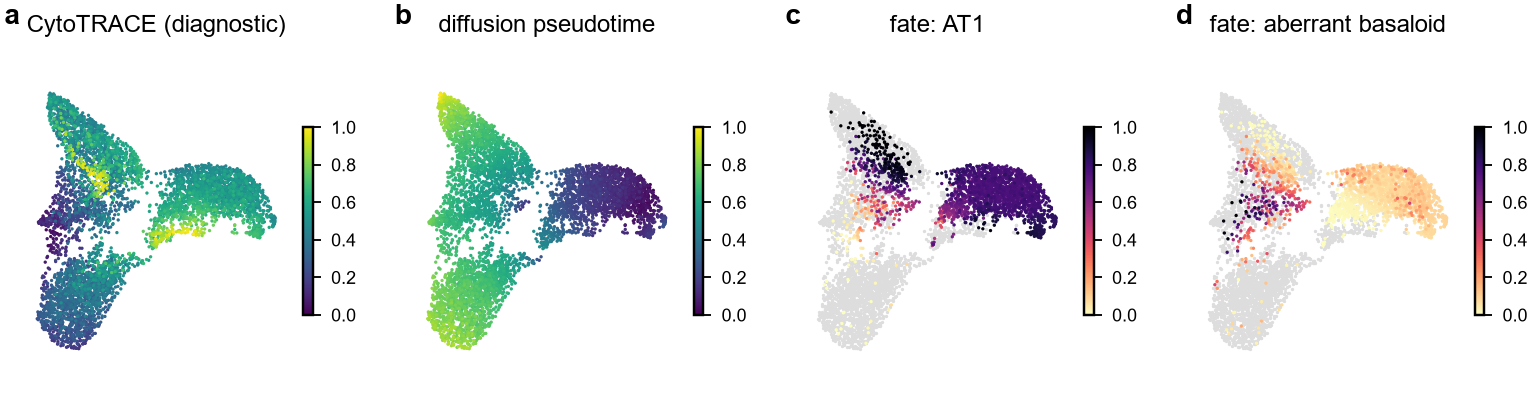

In [8]:
fig, axes = plt.subplots(1, 4, figsize=figsize(183, 50))
xy = adata.obsm["X_umap"]
for ax, (col, title, cmap) in zip(axes, [("ct_pseudotime", "CytoTRACE (diagnostic)", "viridis"),
                                         ("dpt_pseudotime", "diffusion pseudotime", "viridis"),
                                         ("fate_AT1", "fate: AT1", "magma_r"),
                                         ("fate_Aberrant basaloid", "fate: aberrant basaloid", "magma_r")]):
    if col.startswith("fate_"):  # fates are defined for the cells in transit; end points in grey
        ax.scatter(xy[~transient, 0], xy[~transient, 1], s=1.2, color="#DDDDDD", lw=0, rasterized=True)
        sca = embedding_scatter(ax, xy[transient], adata.obs.loc[transient, col], cmap=cmap, s=1.2,
                                order="value", vmin=0, vmax=1)
    else:
        sca = embedding_scatter(ax, xy, adata.obs[col], cmap=cmap, s=1.2, order="value")
    plt.colorbar(sca, ax=ax, shrink=0.55)
    ax.set_title(title)
for a, l in zip(axes, "abcd"):
    panel_label(a, l, x=-0.08)
fig.tight_layout()
save_figure(fig, "Fig4_pseudotime_fates", FIG)
plt.show()

### Do transitional cells from IPF lungs lean towards the aberrant fate?
Compared per **donor** (mean over cells), not per cell. Only donors with ≥ 10
transitional cells are used, so the comparison has little power: no difference
here means the fate bias is not *detectably* different, not that IPF and
control transitional cells are equivalent. What differs strongly between the
conditions is how many aberrant basaloid cells there are (Notebook 06).

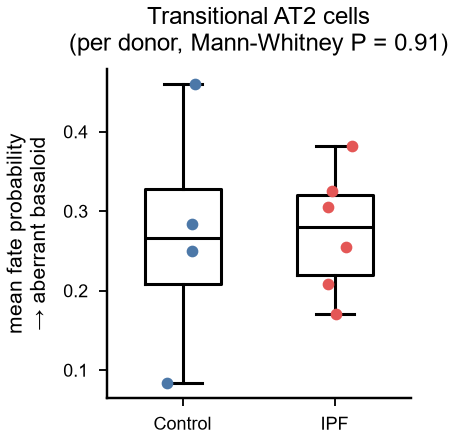

In [9]:
tr = adata.obs[adata.obs["cell_type"] == "Transitional AT2"]
don = tr.groupby("donor_id", observed=True).agg(diagnosis=("diagnosis", "first"), n=("diagnosis", "size"),
                                                fate_basaloid=("fate_Aberrant basaloid", "mean"),
                                                fate_AT1=("fate_AT1", "mean"))
don = don[(don["n"] >= 10) & don["diagnosis"].isin(["Control", "IPF"])]
write_table(don.round(3), TAB / "transitional_fate_per_donor")
from scipy.stats import mannwhitneyu  # noqa: E402

p = mannwhitneyu(don.loc[don.diagnosis == "IPF", "fate_basaloid"], don.loc[don.diagnosis == "Control", "fate_basaloid"]).pvalue
fig, ax = plt.subplots(figsize=figsize(45, 50))
for i, dx in enumerate(["Control", "IPF"]):
    v = don.loc[don.diagnosis == dx, "fate_basaloid"]
    ax.boxplot(v, positions=[i], widths=0.5, showfliers=False, medianprops={"color": "black"})
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), v, s=8, color=CONDITION_COLORS[dx], zorder=3)
ax.set_xticks([0, 1], ["Control", "IPF"])
ax.set_ylabel("mean fate probability\n→ aberrant basaloid")
ax.set_title(f"Transitional AT2 cells\n(per donor, Mann-Whitney P = {p:.2g})")
save_figure(fig, "Fig4_transitional_fate_by_donor", FIG)
plt.show()

## 5. Genes tracking commitment to the aberrant basaloid fate
CellRank lineage drivers: correlation of each gene's expression with the fate
probability, among AT2, transitional and aberrant basaloid cells.

In [10]:
drivers = g.compute_lineage_drivers(lineages=["Aberrant basaloid"], cluster_key="cell_type",
                                    clusters=["AT2", "Transitional AT2", "Aberrant basaloid"])
write_table(drivers.head(300), TAB / "lineage_drivers_aberrant_basaloid")
top_drivers = drivers.index[:30].tolist()
print(", ".join(top_drivers))

MDK, SOX4, COL1A1, KRT17, MMP7, IGFBP7, LBH, MARCKSL1, KRT7, FN1, FHL2, OCIAD2, TACSTD2, TM4SF1, DST, IL32, PRSS2, DPYSL3, STMN1, SERINC2, CD24, ANXA2, TUBA1A, SLCO2A1, CRLF1, PALLD, PTGS2, ITGAV, ITGA2, TMEM98


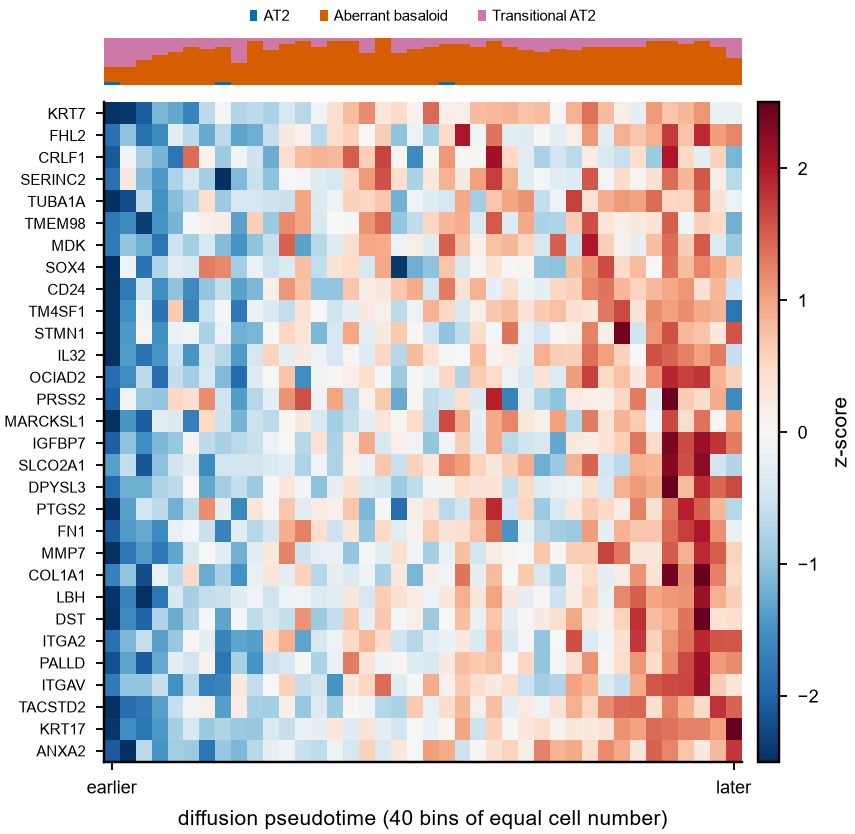

In [11]:
# expression trends along the path into the aberrant basaloid state: cells whose aberrant basaloid
# fate is at least their AT1 fate (almost only transitional AT2 cells; AT2 cells favour AT1) and the
# aberrant basaloid cells, ordered by DPT and binned; the bar on top shows the cell types per bin
path = adata[adata.obs["cell_type"].isin(["AT2", "Transitional AT2", "Aberrant basaloid"])
             & (adata.obs["fate_Aberrant basaloid"] >= adata.obs["fate_AT1"])].copy()
order = path.obs["dpt_pseudotime"].rank(method="first")
bins = pd.qcut(order, 40, labels=False)
expr = pd.DataFrame(path[:, top_drivers].X.toarray(), index=path.obs_names, columns=top_drivers)
trend = expr.groupby(bins.values).mean()
trend = (trend - trend.mean()) / trend.std()
comp = pd.crosstab(bins.values, path.obs["cell_type"].astype(str), normalize="index")

fig = plt.figure(figsize=figsize(100, 110))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 14], width_ratios=[30, 1], hspace=0.05, wspace=0.05)
axb = fig.add_subplot(gs[0, 0])
bottom = np.zeros(len(comp))
for ct in comp.columns:
    axb.bar(np.arange(len(comp)), comp[ct], bottom=bottom, color=colors[ct], width=1.0, label=ct)
    bottom += comp[ct].to_numpy()
axb.set_xlim(-0.5, len(comp) - 0.5)
axb.axis("off")
axb.legend(ncol=3, fontsize=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
axh = fig.add_subplot(gs[1, 0])
peak = trend.idxmax().sort_values().index
im = axh.imshow(trend[peak].T, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, interpolation="nearest")
axh.set_yticks(range(len(peak)), peak, fontsize=5)
axh.set_xticks([0, len(trend) - 1], ["earlier", "later"])
axh.set_xlabel("diffusion pseudotime (40 bins of equal cell number)")
cax = fig.add_subplot(gs[1, 1])
fig.colorbar(im, cax=cax, label="z-score")
save_figure(fig, "Fig4_driver_gene_trends", FIG)
plt.show()

## 6. Aberrant basaloid signature by **paired pseudobulk** (within IPF donors)
A signature for the validation cohort is defined by comparing aberrant
basaloid cells with the other alveolar/basal epithelial cells *of the same
donor* (edgeR, design `~ donor + group`). Pairing removes donor effects; using
the donor-level sums avoids the pseudoreplication of a per-cell Wilcoxon test.

In [12]:
ref_types = ["AT2", "Transitional AT2", "AT1", "Basal"]
mask = (full.obs["cell_type"].isin(["Aberrant basaloid", *ref_types]) & (full.obs["diagnosis"] == "IPF")).to_numpy()
epi = ad.AnnData(X=full.layers["counts"][mask], obs=full.obs.loc[mask, ["donor_id", "cell_type"]].copy(),
                 var=full.var[[]].copy())
epi.obs["group"] = np.where(epi.obs["cell_type"] == "Aberrant basaloid", "Basaloid", "OtherAlveolar")
epi.obs["pb_sample"] = epi.obs["donor_id"].astype(str) + "__" + epi.obs["group"]
epi.obs["signature"] = pd.Categorical(["aberrant_basaloid"] * epi.n_obs)
pb = pseudobulk.aggregate(epi, "signature", "pb_sample", "group", covariates=["donor_id"], layer=None, min_cells=10)
counts, meta = pb["aberrant_basaloid"]
both = meta.groupby("donor_id")["condition"].nunique()
keep = meta.index[meta["donor_id"].isin(both[both == 2].index)]
print(f"{len(keep) // 2} IPF donors with >= 10 aberrant basaloid and >= 10 reference cells")
sig_in, sig_out = P.processed / "pseudobulk" / "signature_in", P.processed / "pseudobulk" / "signature_out"
pseudobulk.write_inputs({"aberrant_basaloid": (counts[keep], meta.loc[keep])}, sig_in, case="Basaloid",
                        control="OtherAlveolar", min_donors=3)
pseudobulk.run_de(rscript(cfg), P.r_scripts / "pseudobulk_de.R", sig_in, sig_out, ["donor_id"], "Basaloid",
                  "OtherAlveolar", methods="edgeR")
sig_res = pseudobulk.read_results(sig_out, "edgeR")
signature = (sig_res[(sig_res.FDR < 0.01) & (sig_res.logFC > 2) & (sig_res.logCPM > 3)]
             .sort_values("logFC", ascending=False).head(50))
write_table(sig_res, TAB / "aberrant_basaloid_vs_alveolar_paired_edgeR", index=False)
write_table(signature[["gene", "logFC", "logCPM", "FDR"]], TAB / "aberrant_basaloid_signature", index=False)
print(len(signature), "signature genes:", ", ".join(signature.gene))

7 IPF donors with >= 10 aberrant basaloid and >= 10 reference cells


05:19:58 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\signature_in J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\signature_out donor_id Basaloid OtherAlveolar edgeR


INFO:ipfatlas:R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\signature_in J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\signature_out donor_id Basaloid OtherAlveolar edgeR


05:20:07 | INFO | R finished: pseudobulk_de.R
[1/1] aberrant_basaloid                case=7 control=7 genes=10948
pseudobulk DE finished


INFO:ipfatlas:R finished: pseudobulk_de.R
[1/1] aberrant_basaloid                case=7 control=7 genes=10948
pseudobulk DE finished


05:20:07 | INFO | edgeR: 1 cell types, 10,948 gene tests


INFO:ipfatlas:edgeR: 1 cell types, 10,948 gene tests


50 signature genes: PRSS2, CGB5, SEMA7A, PRSS1, CDH2, CLDN6, TRBC2, NKAIN4, TUBB2B, PGBD5, RP11-519G16.5, MXRA8, BICC1, BAAT, PCP4, SPOCD1, TUBB3, PLD5, COL6A2, SLCO2A1, PTHLH, RASSF2, KDR, CAPN6, SPINK1, COL1A1, PXDN, EPHB2, CNTNAP2, CMTM3, TMEM233, DKK1, CREB5, PLAU, LTB, SMOC1, AMIGO2, CDKN2A, MEX3A, GLIPR1, CASC15, CRLF1, CST6, NRK, VCAN, CTXN1, FN1, NEURL1B, VSIG1, MFAP2


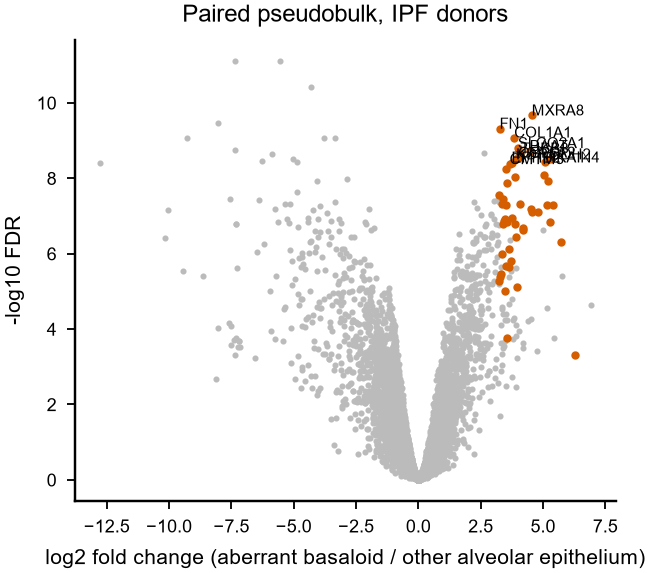

In [13]:
fig, ax = plt.subplots(figsize=figsize(80, 70))
sig_res["mlog10"] = -np.log10(sig_res["FDR"].clip(lower=1e-300))
ax.scatter(sig_res.logFC, sig_res.mlog10, s=1, color="#BBBBBB", rasterized=True)
s = sig_res.gene.isin(signature.gene)
ax.scatter(sig_res.loc[s, "logFC"], sig_res.loc[s, "mlog10"], s=3, color=colors["Aberrant basaloid"])
for _, r in sig_res[s].nlargest(12, "mlog10").iterrows():
    ax.annotate(r.gene, (r.logFC, r.mlog10), fontsize=5)
ax.set_xlabel("log2 fold change (aberrant basaloid / other alveolar epithelium)")
ax.set_ylabel("-log10 FDR")
ax.set_title("Paired pseudobulk, IPF donors")
save_figure(fig, "S9_basaloid_signature_volcano", FIG)
plt.show()

## 7. Export input for pySCENIC (Linux workstation)
Gene-regulatory network inference (GRNBoost2 + cisTarget motif pruning +
AUCell; Aibar *et al.* 2017; Van de Sande *et al.* 2020) is run on the Linux
machine (`linux_upstream/scripts/08_pyscenic.sh`). We export raw counts of the
subsampled lineage cells, with genes detected in ≥1 % of them.

In [14]:
import loompy  # noqa: E402

det = np.asarray((adata.layers["counts"] > 0).mean(axis=0)).ravel()
genes = adata.var_names[det >= 0.01]
loom_path = P.root / "linux_upstream" / "input" / "scenic_input.loom"
loom_path.parent.mkdir(parents=True, exist_ok=True)
loom_path.unlink(missing_ok=True)
mat = adata[:, genes].layers["counts"].T.tocsr().astype(np.float32)
loompy.create(str(loom_path), mat.toarray(),
              row_attrs={"Gene": np.array(genes)},
              col_attrs={"CellID": np.array(adata.obs_names), "cell_type": adata.obs["cell_type"].astype(str).values,
                         "diagnosis": adata.obs["diagnosis"].astype(str).values,
                         "donor_id": adata.obs["donor_id"].astype(str).values})
print(f"wrote {loom_path} ({len(genes):,} genes x {adata.n_obs:,} cells)")

wrote J:\Portfolio_projects\Projects\scRNA\linux_upstream\input\scenic_input.loom (13,289 genes x 5,892 cells)


In [15]:
adata.obsm["fate_probabilities"] = fates.to_numpy()
adata.uns["fate_names"] = list(fates.columns)
for k in ["Ms", "Mu"]:
    adata.layers.pop(k, None)
# CellRank stores macrostate memberships as its own Lineage array type, which h5ad cannot write
for k in list(adata.obsm):
    if type(adata.obsm[k]).__module__.startswith("cellrank"):
        adata.obsm[k] = np.asarray(adata.obsm[k])
adata.write_h5ad(P.processed / "epithelial_trajectory.h5ad", compression="lzf")